# 08. Sazonalidade mensal (P2)

**Pergunta 2** — Existe sazonalidade mensal consistente, e como o padrão varia entre os estados e entre a capital e o interior de cada estado?

| Entrada | Saída |
|---|---|
| `notificacao_dengue_ne`, `municipio` (tratadas) | perfil mensal, mês de maior ocorrência, mês central e concentração por estado, com comparação capital × interior |

**Método.** Casos prováveis com data válida dos primeiros sintomas entre 2000 e 2025. O ano e o mês vêm de `dt_sintomas`. Cada série anual tem pelo menos 100 casos e é convertida em proporções mensais que somam 100%, de modo que os anos tenham o mesmo peso no perfil médio.

- **Mês de maior ocorrência** — mês com a maior proporção de casos no perfil apresentado. Em caso de empate, a tabela mostra todos os meses empatados.
- **Mês central da sazonalidade** — média circular dos meses ponderada pela proporção de casos no ano. Dezembro e janeiro são vizinhos no cálculo. O mês central típico de cada série é a média circular dos centros anuais, com o mesmo peso para cada ano.
- **Concentração R** — mede quanto os casos se concentram em torno de uma época do ano. Valores próximos de 1 indicam maior concentração.

**Capital × interior.** Em cada estado, os casos são agrupados pelo município de residência. O grupo capital reúne os residentes da capital e o grupo interior reúne os residentes dos demais municípios.

**Neste notebook**
1. Dados
2. Nordeste: o padrão se repete todo ano?
3. Perfil médio por estado
4. Maior ocorrência, mês central e consistência por estado
5. Capital × interior
6. Achados

In [1]:
import sys
from pathlib import Path
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.append(str(RAIZ / "src"))

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from eda import eda

eda.estilo()

## 1. Dados

In [2]:
from config import ANO_FIM, ANO_INICIO

MIN_CASOS = 100
mes = eda.casos_mes()
print(f"Casos prováveis com início dos sintomas entre {ANO_INICIO} e {ANO_FIM}: {mes.casos.sum():,}")


def proporcao_mensal(df, chaves):
    """Proporção (%) dos casos de cada grupo-ano em cada mês; descarta grupo-anos com menos de MIN_CASOS."""
    t = (df.groupby(chaves + ["ano", "mes"], observed=True).casos.sum()
           .unstack("mes", fill_value=0).reindex(columns=range(1, 13), fill_value=0))
    t = t[t.sum(axis=1) >= MIN_CASOS]
    return t.div(t.sum(axis=1), axis=0) * 100


def maior_ocorrencia(perfil):
    """Nomes dos meses com a proporção máxima, incluindo empates."""
    meses = perfil.index[np.isclose(perfil, perfil.max())]
    return " / ".join(eda.MESES[m - 1] for m in meses)


def circulares(prop):
    """Mês central e concentração R de cada linha de proporções mensais."""
    valores = [eda.estatisticas_circulares(linha) for linha in prop.to_numpy()]
    return pd.DataFrame(valores, index=prop.index, columns=["centro", "R"])


prop_ne = proporcao_mensal(mes.assign(regiao="NE"), ["regiao"]).droplevel("regiao")
prop_uf = proporcao_mensal(mes, ["uf"])
circ_ne, circ_uf = circulares(prop_ne), circulares(prop_uf)
total_uf_ano = len(eda.UFS) * (ANO_FIM - ANO_INICIO + 1)
print(f"Estado-anos analisados: {len(prop_uf)} de {total_uf_ano} (os demais têm menos de {MIN_CASOS} casos)")

Casos prováveis com início dos sintomas entre 2000 e 2025: 4,169,990
Estado-anos analisados: 233 de 234 (os demais têm menos de 100 casos)


## 2. Nordeste: o padrão se repete todo ano?
Cada linha cinza é um ano; a linha azul é a média dos anos.

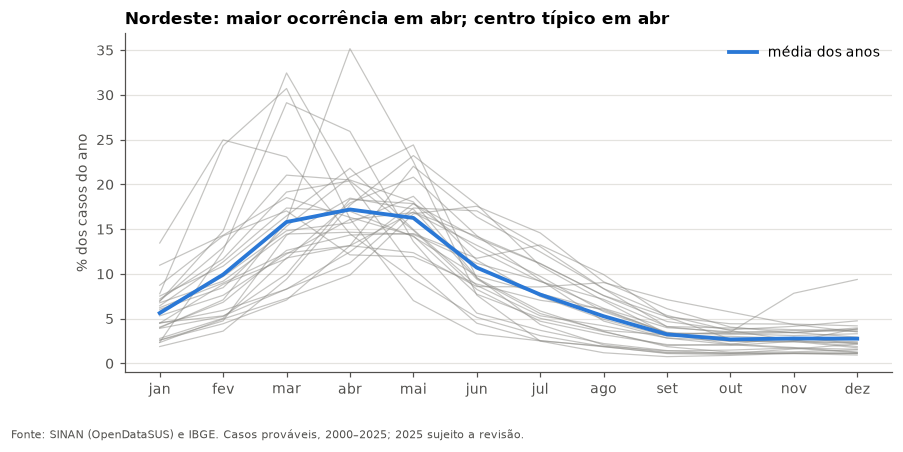

Mês central típico: abr (4.35); 77% dos anos com centro a até 1 mês dele
Concentração R: mediana 0.46 (de 0.23 a 0.72)
Casos de janeiro a junho: mediana 75% do ano (de 59% a 92%)


In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
for _, linha in prop_ne.iterrows():
    ax.plot(range(1, 13), linha, color=eda.COR["referencia"], lw=0.8, alpha=0.5)
media_ne = prop_ne.mean()
ax.plot(range(1, 13), media_ne, color=eda.COR["principal"], lw=2.5, label="média dos anos")
ax.set_xticks(range(1, 13), eda.MESES)
ax.set_ylabel("% dos casos do ano")
centro_ne = eda.media_circular(circ_ne.centro)
ax.set_title(f"Nordeste: maior ocorrência em {maior_ocorrencia(media_ne)}; centro típico em {eda.nome_mes(centro_ne)}")
ax.legend(loc="upper right")
eda.nota(fig)
plt.show()

perto = (eda.distancia_meses(circ_ne.centro, centro_ne) <= 1).mean() * 100
semestre = prop_ne[range(1, 7)].sum(axis=1)
print(f"Mês central típico: {eda.nome_mes(centro_ne)} ({centro_ne:.2f}); {perto:.0f}% dos anos com centro a até 1 mês dele")
print(f"Concentração R: mediana {circ_ne.R.median():.2f} (de {circ_ne.R.min():.2f} a {circ_ne.R.max():.2f})")
print(f"Casos de janeiro a junho: mediana {semestre.median():.0f}% do ano (de {semestre.min():.0f}% a {semestre.max():.0f}%)")

In [4]:
circ_ne.assign(**{
    "mês de maior ocorrência": prop_ne.apply(maior_ocorrencia, axis=1),
    "mês central": circ_ne.centro.map(eda.nome_mes),
}).rename(columns={"centro": "centro (mês)"}).round(2)

,centro (mês),R,mês de maior ocorrência,mês central
ano,,,,
2000,3.48,0.48,mar,mar
2001,4.32,0.44,mai,abr
2002,2.94,0.67,mar,mar
2003,3.81,0.61,mar,abr
2004,3.62,0.35,mar,abr
2005,5.18,0.39,mai,mai
2006,5.47,0.40,mai,mai
2007,4.67,0.41,mai,mai
2008,4.06,0.72,abr,abr


## 3. Perfil médio por estado
Porcentagem média dos casos do ano em cada mês.

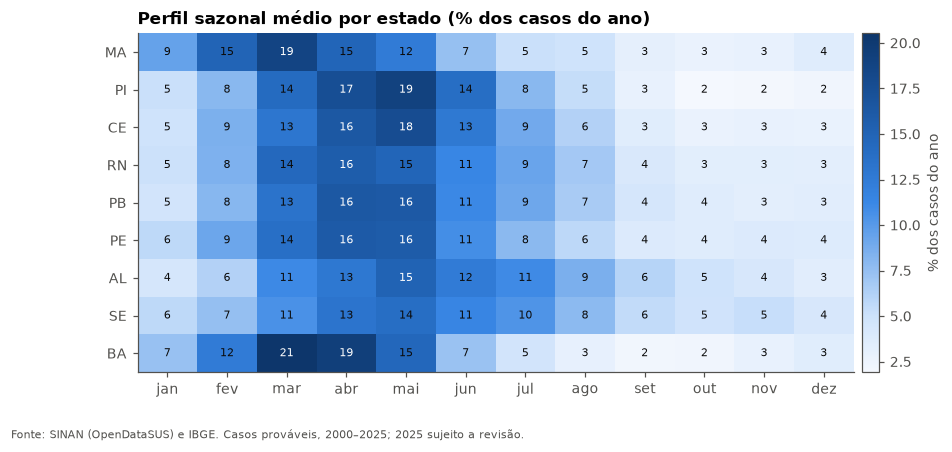

In [5]:
perfil_uf = prop_uf.groupby("uf", observed=True).mean().loc[eda.UFS]
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(perfil_uf, aspect="auto", cmap=eda.SEQUENCIAL)
for i, uf in enumerate(perfil_uf.index):
    for j in range(12):
        v = perfil_uf.iloc[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5,
                color="white" if v > 15 else eda.COR["texto"])
ax.set_xticks(range(12), eda.MESES)
ax.set_yticks(range(len(perfil_uf)), perfil_uf.index)
ax.grid(False)
ax.set_title("Perfil sazonal médio por estado (% dos casos do ano)")
fig.colorbar(im, ax=ax, label="% dos casos do ano", pad=0.01)
eda.nota(fig)
plt.show()

## 4. Maior ocorrência, mês central e consistência por estado

**% anos a até 1 mês do centro típico** mede a regularidade do mês central de um ano para outro. O mês de maior ocorrência é lido no perfil médio de cada estado.

In [6]:
linhas = []
for uf in eda.UFS:
    c = circ_uf.loc[uf]
    tipico = eda.media_circular(c.centro)
    linhas.append({
        "uf": uf, "anos": len(c), "maior ocorrência": maior_ocorrencia(perfil_uf.loc[uf]),
        "mês central típico": eda.nome_mes(tipico), "centro típico (mês)": tipico,
        "% anos a até 1 mês do centro típico": (eda.distancia_meses(c.centro, tipico) <= 1).mean() * 100,
        "R mediano": c.R.median(),
        "% jan–jun": prop_uf.loc[uf][range(1, 7)].sum(axis=1).median(),
    })
saz_uf = pd.DataFrame(linhas).set_index("uf")
saz_uf.sort_values("centro típico (mês)").round(2)

,anos,maior ocorrência,mês central típico,centro típico (mês),% anos a até 1 mês do centro típico,R mediano,% jan–jun
uf,,,,,,,
MA,26,mar,mar,3.45,76.92,0.49,79.48
BA,26,mar,abr,3.65,88.46,0.53,82.27
PE,26,abr,mai,4.53,57.69,0.45,67.75
PI,26,mai,mai,4.55,80.77,0.52,78.20
CE,26,mai,mai,4.60,73.08,0.50,74.08
RN,26,abr,mai,4.67,57.69,0.47,69.34
PB,25,abr,mai,4.73,68.00,0.44,70.05
SE,26,mai,mai,5.14,46.15,0.38,60.65
AL,26,mai,mai,5.42,53.85,0.41,63.10


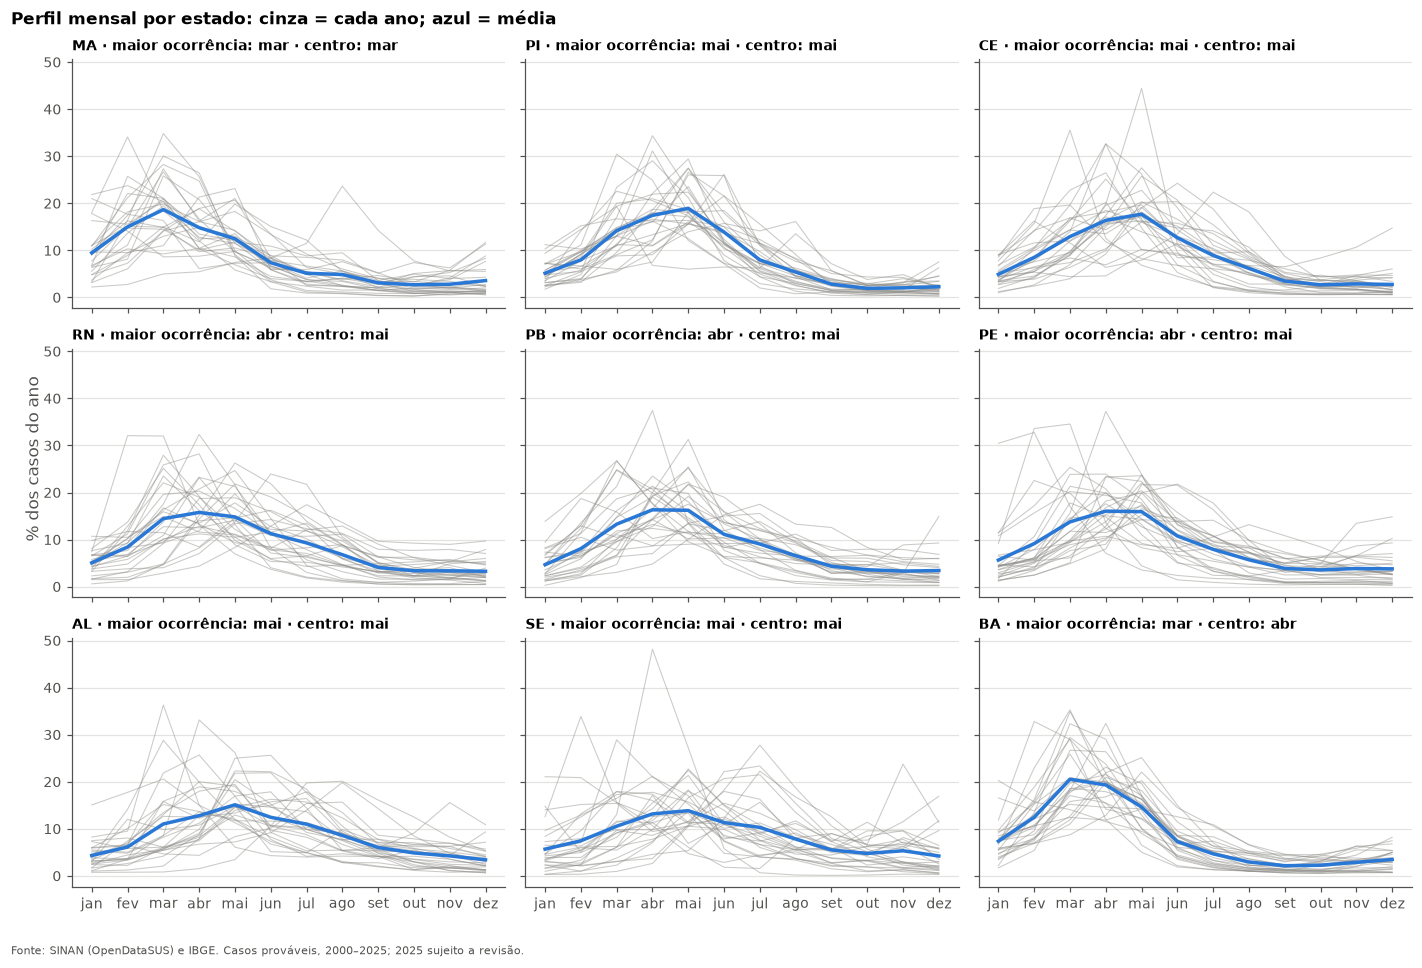

In [7]:
fig, axs = plt.subplots(3, 3, figsize=(13, 8.5), sharex=True, sharey=True)
for ax, uf in zip(axs.ravel(), eda.UFS):
    for _, linha in prop_uf.loc[uf].iterrows():
        ax.plot(range(1, 13), linha, color=eda.COR["referencia"], lw=0.7, alpha=0.45)
    ax.plot(range(1, 13), perfil_uf.loc[uf], color=eda.COR["principal"], lw=2.3)
    maior = saz_uf.loc[uf, "maior ocorrência"]
    central = saz_uf.loc[uf, "mês central típico"]
    ax.set_title(f"{uf} · maior ocorrência: {maior} · centro: {central}", fontsize=9)
    ax.set_xticks(range(1, 13), eda.MESES)
fig.supylabel("% dos casos do ano", color=eda.COR["texto2"])
fig.suptitle("Perfil mensal por estado: cinza = cada ano; azul = média", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
eda.nota(fig)
plt.show()

## 5. Capital × interior

Em cada estado, mantemos apenas os anos com pelo menos 100 casos na capital e 100 no interior. Os dois perfis e suas estatísticas usam esse mesmo conjunto de anos, que pode variar entre estados.

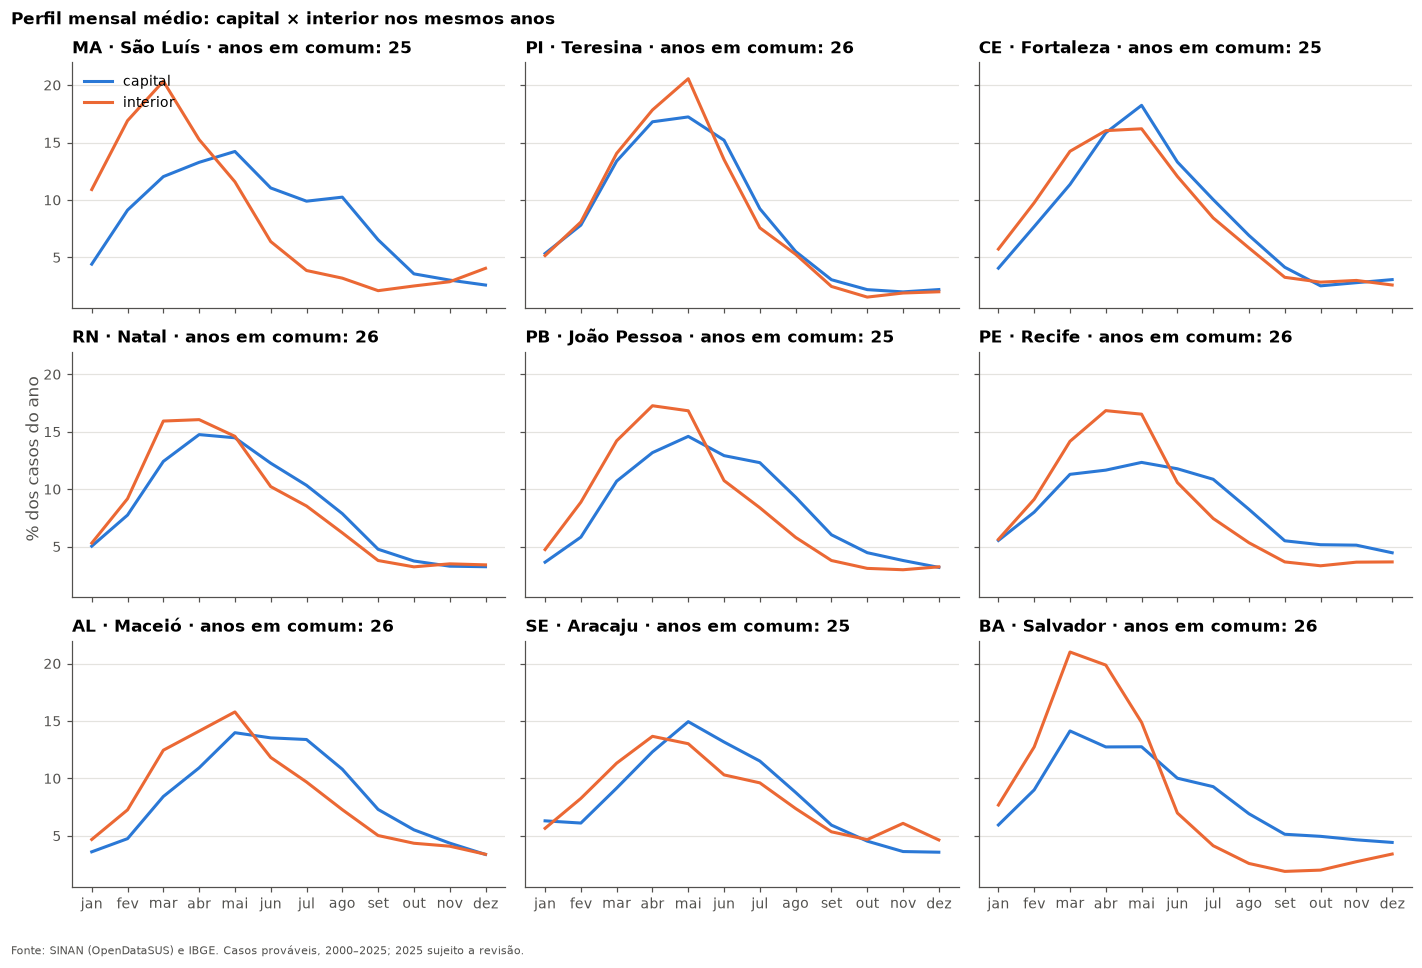

In [8]:
grupos = ["capital", "interior"]
prop_g = proporcao_mensal(mes, ["uf", "grupo"])
# Após o corte de 100 casos, uma dupla UF–ano é elegível se os dois grupos estiverem presentes.
grupos_por_ano = prop_g.groupby(level=["uf", "ano"], observed=True)[1].transform("size")
prop_g = prop_g.loc[grupos_por_ano.eq(len(grupos))]
circ_g = circulares(prop_g)
perfil_g = prop_g.groupby(["uf", "grupo"], observed=True).mean()
cor_g = {"capital": eda.COR["principal"], "interior": eda.COR["comparacao"]}

fig, axs = plt.subplots(3, 3, figsize=(13, 8.5), sharex=True, sharey=True)
for ax, uf in zip(axs.ravel(), eda.UFS):
    anos = 0
    if uf in perfil_g.index.get_level_values("uf"):
        for g in grupos:
            ax.plot(range(1, 13), perfil_g.loc[(uf, g)], color=cor_g[g], label=g)
        anos = len(prop_g.loc[(uf, "capital")])
    ax.set_title(f"{uf} · {eda.CAPITAL_UF[uf]} · anos em comum: {anos}")
    ax.set_xticks(range(1, 13), eda.MESES)
primeiro_com_dados = next((ax for ax in axs.ravel() if ax.lines), None)
if primeiro_com_dados is not None:
    primeiro_com_dados.legend(loc="upper left")
fig.supylabel("% dos casos do ano", color=eda.COR["texto2"])
fig.suptitle("Perfil mensal médio: capital × interior nos mesmos anos", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
eda.nota(fig)
plt.show()

In [9]:
linhas = []
for uf, grupos_uf in circ_g.groupby(level="uf", observed=True):
    linha = {"uf": uf, "anos em comum": grupos_uf.index.get_level_values("ano").nunique()}
    for grupo in grupos:
        c = grupos_uf.xs(grupo, level="grupo")
        centro = eda.media_circular(c.centro)
        linha[f"maior ocorrência ({grupo})"] = maior_ocorrencia(perfil_g.loc[(uf, grupo)])
        linha[f"mês central ({grupo})"] = eda.nome_mes(centro)
        linha[f"centro ({grupo})"] = centro
        linha[f"R mediano ({grupo})"] = c.R.median()
    d = linha["centro (interior)"] - linha["centro (capital)"]
    linha["centro interior − capital (meses)"] = (d + 6) % 12 - 6
    linhas.append(linha)
comp = pd.DataFrame(linhas).set_index("uf") if linhas else pd.DataFrame()
comp.round(2)

,anos em comum,maior ocorrência (capital),mês central (capital),centro (capital),R mediano (capital),maior ocorrência (interior),mês central (interior),centro (interior),R mediano (interior),centro interior − capital (meses)
uf,,,,,,,,,,
MA,25,mai,mai,5.14,0.45,mar,mar,3.18,0.52,-1.96
PI,26,mai,mai,4.64,0.57,mai,mai,4.51,0.57,-0.13
CE,25,mai,mai,4.96,0.61,mai,abr,4.40,0.53,-0.56
RN,26,abr,mai,4.94,0.42,abr,abr,4.44,0.47,-0.50
PB,25,mai,mai,5.43,0.49,abr,mai,4.54,0.49,-0.89
PE,26,mai,mai,5.40,0.38,abr,abr,4.47,0.45,-0.93
AL,26,mai,jun,5.96,0.43,mai,mai,5.19,0.46,-0.77
SE,25,mai,mai,5.35,0.41,abr,mai,4.97,0.39,-0.38
BA,26,mar,abr,4.48,0.39,mar,abr,3.58,0.55,-0.90


## 6. Achados

Os resultados abaixo são calculados a partir das tabelas do notebook.

In [10]:
from IPython.display import Markdown, display

cedo = saz_uf["centro típico (mês)"].idxmin()
tarde = saz_uf["centro típico (mês)"].idxmax()
maior_uf = ", ".join(f"{uf}: {mes}" for uf, mes in saz_uf["maior ocorrência"].items())
achados = [
    f"- **Nordeste.** A mediana dos casos anuais entre janeiro e junho foi de {semestre.median():.0f}% "
    f"(de {semestre.min():.0f}% a {semestre.max():.0f}%). No perfil médio, a maior ocorrência foi em "
    f"**{maior_ocorrencia(media_ne)}**. O mês central típico foi **{eda.nome_mes(centro_ne)}** "
    f"e {perto:.0f}% dos anos tiveram centro a até um mês dele.",
    f"- **Estados.** O mês central típico mais cedo foi em {cedo} ({saz_uf.loc[cedo, 'mês central típico']}) "
    f"e o mais tarde em {tarde} ({saz_uf.loc[tarde, 'mês central típico']}). "
    f"Meses de maior ocorrência nos perfis médios — {maior_uf}.",
]
if comp.empty:
    achados.append("- **Capital × interior.** Nenhum estado teve anos elegíveis nos dois grupos.")
else:
    diferenca = comp["centro interior − capital (meses)"]
    adiantados = ", ".join(diferenca.index[diferenca.round(2) < 0]) or "nenhum"
    atrasados = ", ".join(diferenca.index[diferenca.round(2) > 0]) or "nenhum"
    iguais = ", ".join(diferenca.index[diferenca.round(2) == 0]) or "nenhum"
    mesmos_maximos = comp["maior ocorrência (capital)"].eq(comp["maior ocorrência (interior)"]).sum()
    achados.append(
        f"- **Capital × interior.** Os estados comparados tiveram de {comp['anos em comum'].min()} a "
        f"{comp['anos em comum'].max()} anos em comum. O mês central do interior foi mais cedo em "
        f"{adiantados}, mais tarde em {atrasados} e igual a duas casas decimais em {iguais}. "
        f"Os meses de maior ocorrência coincidiram em {mesmos_maximos} de {len(comp)} estados comparados."
    )
display(Markdown("\n".join(achados)))

- **Nordeste.** A mediana dos casos anuais entre janeiro e junho foi de 75% (de 59% a 92%). No perfil médio, a maior ocorrência foi em **abr**. O mês central típico foi **abr** e 77% dos anos tiveram centro a até um mês dele.
- **Estados.** O mês central típico mais cedo foi em MA (mar) e o mais tarde em AL (mai). Meses de maior ocorrência nos perfis médios — MA: mar, PI: mai, CE: mai, RN: abr, PB: abr, PE: abr, AL: mai, SE: mai, BA: mar.
- **Capital × interior.** Os estados comparados tiveram de 25 a 26 anos em comum. O mês central do interior foi mais cedo em MA, PI, CE, RN, PB, PE, AL, SE, BA, mais tarde em nenhum e igual a duas casas decimais em nenhum. Os meses de maior ocorrência coincidiram em 5 de 9 estados comparados.